# Modul 5: Convolutional Neural Network Dasar

**Nama:** Ahmad Rizqi
**NIM:** 122450138
**Kelas:** RA
**Tanggal:** 2026-10-14

Simpan berkas ini sebagai `M05_122450138.ipynb` sebelum mulai mengerjakan.

## Petunjuk

1. Lengkapi semua jawaban dan jalankan pemeriksaan yang berisi `cek(...)` atau `assert`.
2. Setiap isian **hitungan tangan** diisi sebelum sel kode sesudahnya dijalankan.
3. Implementasi manual hanya boleh memakai indexing, perkalian elemen, penjumlahan, `F.pad`, dan `torch.flip`. `F.conv2d` dan autograd hanya dipakai sebagai pembanding.
4. Seluruh verifikasi memakai `torch.float64` dan `torch.allclose`.
5. Protokol tugas: subset $10\,000$/$2\,000$, Adam $10^{-3}$, batch $128$, $10$ epoch ($790$ update). Bila memakai Fashion-MNIST karena keterbatasan CPU, sebutkan pada laporan.
6. Luaran: `M05_122450138.ipynb`, `M05_122450138.pdf`, dan `M05_122450138_metrics.csv`.

In [50]:
import platform
import random
import statistics
import time
from pathlib import Path

import matplotlib
try:
    from IPython import get_ipython
    if get_ipython() is None:
        matplotlib.use('Agg')
    else:
        matplotlib.use('module://matplotlib_inline.backend_inline')
except Exception:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import CIFAR10, FashionMNIST

DATASET = 'fashion'      # ganti ke 'fashion' bila hanya tersedia CPU
NIM = '122450138'                 # contoh: '120450123'
SEED = int(str(NIM)[-4:]) if str(NIM).isdigit() else 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DT = torch.float64

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def cek(nama, hasil, acuan):
    """Sel pemeriksaan: shape harus sama dan nilai lolos torch.allclose."""
    assert hasil is not None and acuan is not None, f'{nama}: hasil atau acuan belum diisi'
    hasil = torch.as_tensor(hasil.detach() if torch.is_tensor(hasil) else hasil, dtype=DT)
    acuan = torch.as_tensor(acuan.detach() if torch.is_tensor(acuan) else acuan, dtype=DT)
    ok = hasil.shape == acuan.shape and torch.allclose(hasil, acuan)
    print(f'[{"OK" if ok else "GAGAL"}] {nama}: shape {tuple(hasil.shape)}')
    assert ok, f'{nama} tidak cocok dengan acuan'

def ukur(fungsi, ulang=10):
    """Median waktu eksekusi `fungsi` dalam detik setelah satu pemanasan."""
    fungsi()
    waktu = []
    for _ in range(ulang):
        mulai = time.perf_counter()
        fungsi()
        waktu.append(time.perf_counter() - mulai)
    return statistics.median(waktu)

seed_everything(SEED)
pd.set_option('display.precision', 4)
print({'python': platform.python_version(), 'torch': torch.__version__,
       'device': str(DEVICE), 'dataset': DATASET, 'seed': SEED})

{'python': '3.11.4', 'torch': '2.14.0+cpu', 'device': 'cpu', 'dataset': 'fashion', 'seed': 138}


## Pre-lab — 10 poin

Kerjakan **sebelum** sesi tanpa menjalankan kode. Gunakan X dan K pada Bagian A.

a. Dengan padding 1 dan stride 2, keluaran berukuran 3×3. Y₀₀ = 1·1 + 2·0 + 0·(−1) + 0·2 + 1·1 + 0·(−1) + 0·1 + 0·0 + 0·0 = 2. Hasil: [[2,3,4],[0,2,6],[3,0,5]].

b. Kolom ke-4 (indeks 4) F.unfold memakai patch baris 1–3 dan kolom 1–3 (indeks basis nol): [[1,3,2],[1,0,1],[0,2,3]], diratakan sebagai [1,3,2,1,0,1,0,2,3].

c. Parameter = 32×(3×3×3 + 1) = 896. Keluaran 32×32×32, sehingga perkalian = 32×3×3×3×32×32 = 884,736.

d. Membalik kernel pada cross-correlation hanya mengubah parameterisasi. Karena kernel dapat dipelajari bebas, jaringan dapat mempelajari kernel yang sudah dibalik; prediksi dan kemampuan optimisasi tetap sama.

## A. Cross-correlation manual

Hitungan: Y₀₀ = 1·1+2·0+0·(−1)+0·2+1·1+3·0+2·0+1·(−1)+0·1 = 1. Y₀₁ = 2·1+0·0+1·(−1)+1·2+3·1+2·0+1·0+0·(−1)+1·1 = 7.

Matriks hasil: [[1,7,6],[4,2,0],[4,1,7]].


In [51]:
X = torch.tensor([[1, 2, 0, 1, 3],
                  [0, 1, 3, 2, 1],
                  [2, 1, 0, 1, 2],
                  [1, 0, 2, 3, 0],
                  [3, 1, 1, 0, 2]], dtype=DT)
K = torch.tensor([[1, 0, -1],
                  [2, 1, 0],
                  [0, -1, 1]], dtype=DT)

def corr2d(X, K):
    """Cross-correlation 2D satu kanal, tanpa padding, stride 1."""
    h, w = K.shape
    Y = torch.zeros(X.shape[0] - h + 1, X.shape[1] - w + 1, dtype=X.dtype, device=X.device)
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Y[i, j] = (X[i:i + h, j:j + w] * K).sum()
    return Y

Y_TANGAN = [[1, 7, 6], [4, 2, 0], [4, 1, 7]]

Y_manual = corr2d(X, K)
print('X ⋆ K =\n', Y_manual)
cek('hitungan tangan vs corr2d', Y_manual, Y_TANGAN)
cek('corr2d vs F.conv2d', Y_manual, F.conv2d(X[None, None], K[None, None])[0, 0])

Y_konvolusi = corr2d(X, torch.flip(K, (0, 1)))
print('X * K (kernel dibalik) =\n', Y_konvolusi)
assert not torch.allclose(Y_konvolusi, Y_manual), 'konvolusi matematis seharusnya berbeda'

X ⋆ K =
 tensor([[1., 7., 6.],
        [4., 2., 0.],
        [4., 1., 7.]], dtype=torch.float64)
[OK] hitungan tangan vs corr2d: shape (3, 3)
[OK] corr2d vs F.conv2d: shape (3, 3)
X * K (kernel dibalik) =
 tensor([[4., 9., 5.],
        [1., 3., 4.],
        [3., 8., 3.]], dtype=torch.float64)


Konvolusi matematis membalik kernel 180° sebelum menggeser, sehingga setiap jendela mengalikan elemen yang berbeda posisinya; hasilnya bukan sekadar perubahan tanda. Keduanya hanya berbeda tanda jika pada semua jendela hasil korelasi kernel terbalik sama dengan negatif hasil kernel asli (misalnya kernel antisimetri terhadap rotasi 180°).


## B. Padding, stride, dan banyak kanal — bagian dari 20 poin

$$Y_{c',i,j}=b_{c'}+\sum_{c}\sum_{u=0}^{k-1}\sum_{v=0}^{k-1}W_{c',c,u,v}\,\tilde{X}_{c,\,si+u,\,sj+v},\qquad
n_\text{keluar}=\left\lfloor\frac{n+2p-d(k-1)-1}{s}\right\rfloor+1$$

In [52]:
def shape_keluar(n, k, p=0, s=1, d=1):
    """Rumus shape satu sumbu spasial, termasuk dilation."""
    return (n + 2 * p - d * (k - 1) - 1) // s + 1

def corr2d_multi(X, W, b=None, stride=1, padding=0):
    """X: (C_in, H, W), W: (C_out, C_in, k, k), b: (C_out,) -> (C_out, H_out, W_out)."""
    c_out, c_in, kh, kw = W.shape
    assert X.shape[0] == c_in, 'kanal masukan tidak cocok dengan kernel'
    Xp = F.pad(X, (padding, padding, padding, padding))
    h_out = shape_keluar(X.shape[1], kh, padding, stride)
    w_out = shape_keluar(X.shape[2], kw, padding, stride)
    Y = torch.zeros(c_out, h_out, w_out, dtype=X.dtype)
    for i in range(h_out):
        for j in range(w_out):
            r, c = i * stride, j * stride
            jendela = Xp[:, r:r + kh, c:c + kw]              # (C_in, k, k)
            Y[:, i, j] = (W * jendela).sum(dim=(1, 2, 3))    # satu nilai per kanal keluaran
    if b is not None:
        Y = Y + b.view(-1, 1, 1)
    return Y

PRELAB_A = [[2, 3, 4], [0, 2, 6], [3, 0, 5]]

Y_s2 = corr2d_multi(X[None], K[None, None], stride=2, padding=1)[0]
print('p=1, s=2:\n', Y_s2)
cek('pre-lab a vs corr2d_multi', Y_s2, PRELAB_A)
cek('corr2d_multi vs F.conv2d (p=1, s=2)', Y_s2,
    F.conv2d(X[None, None], K[None, None], stride=2, padding=1)[0, 0])

Xm = torch.tensor([[[1, 0, 2], [3, 1, 0], [0, 2, 1]],
                   [[2, 1, 0], [0, 1, 3], [1, 0, 2]]], dtype=DT)
Wm = torch.tensor([[[[1, -1], [0, 2]], [[0, 1], [-1, 1]]],
                   [[[1, 0], [0, 1]], [[1, 1], [1, 1]]]], dtype=DT)
bm = torch.tensor([0.5, -1.0], dtype=DT)
Ym_modul = torch.tensor([[[5.5, 0.5], [6.5, 8.5]],
                         [[5.0, 4.0], [6.0, 7.0]]], dtype=DT)

Ym = corr2d_multi(Xm, Wm, bm)
cek('contoh dua kanal vs modul', Ym, Ym_modul)

conv = nn.Conv2d(2, 2, 2).double()

with torch.no_grad():
    conv.weight.copy_(Wm)
    conv.bias.copy_(bm)

cek('contoh dua kanal vs nn.Conv2d', conv(Xm[None])[0], Ym)
print('parameter nn.Conv2d(2, 2, 2):', sum(q.numel() for q in conv.parameters()))

p=1, s=2:
 tensor([[2., 3., 4.],
        [0., 2., 6.],
        [3., 0., 5.]], dtype=torch.float64)
[OK] pre-lab a vs corr2d_multi: shape (3, 3)
[OK] corr2d_multi vs F.conv2d (p=1, s=2): shape (3, 3)
[OK] contoh dua kanal vs modul: shape (2, 2, 2)
[OK] contoh dua kanal vs nn.Conv2d: shape (2, 2, 2)
parameter nn.Conv2d(2, 2, 2): 18


In [53]:
KONFIGURASI = [  # (C_in, C_out, n, k, s, p)
    (3, 4, 7, 3, 1, 1),
    (3, 4, 9, 5, 2, 2),
    (1, 2, 6, 3, 2, 0),
    (2, 3, 8, 5, 1, 0),
    (3, 4, 11, 3, 2, 1),
]
gen = torch.Generator().manual_seed(SEED)
baris = []
for c_in, c_out, n, k, s, p in KONFIGURASI:
    Xr = torch.randn(c_in, n, n, dtype=DT, generator=gen)
    Wr = torch.randn(c_out, c_in, k, k, dtype=DT, generator=gen)
    br = torch.randn(c_out, dtype=DT, generator=gen)
    Y_manual = corr2d_multi(Xr, Wr, br, stride=s, padding=p)
    Y_acuan = F.conv2d(Xr[None], Wr, br, stride=s, padding=p)[0]
    shape_rumus = (c_out, shape_keluar(n, k, p, s), shape_keluar(n, k, p, s))
    baris.append({'C_in': c_in, 'C_out': c_out, 'n': n, 'k': k, 's': s, 'p': p,
                  'shape_rumus': shape_rumus, 'shape_manual': tuple(Y_manual.shape),
                  'shape_cocok': shape_rumus == tuple(Y_acuan.shape) == tuple(Y_manual.shape),
                  'allclose': torch.allclose(Y_manual, Y_acuan)})
tabel_b = pd.DataFrame(baris)
display(tabel_b)
assert tabel_b['shape_cocok'].all() and tabel_b['allclose'].all(), 'ada konfigurasi yang belum lolos'
print('kelima konfigurasi lolos')

,C_in,C_out,n,k,s,p,shape_rumus,shape_manual,shape_cocok,allclose
0,3,4,7,3,1,1,"(4, 7, 7)","(4, 7, 7)",True,True
1,3,4,9,5,2,2,"(4, 5, 5)","(4, 5, 5)",True,True
2,1,2,6,3,2,0,"(2, 2, 2)","(2, 2, 2)",True,True
3,2,3,8,5,1,0,"(3, 4, 4)","(3, 4, 4)",True,True
4,3,4,11,3,2,1,"(4, 6, 6)","(4, 6, 6)",True,True


kelima konfigurasi lolos


Untuk n=6, k=3, s=2, p=0, jendela mulai pada indeks 0 dan 2. Baris dan kolom indeks 5 (baris/kolom ke-6) tidak pernah dikunjungi.


## C. Unfold dan biaya komputasi — 10 poin

$$\operatorname{vec}(\mathbf{Y})=\mathbf{W}_\text{flat}\,\mathbf{U}+\mathbf{b}\mathbf{1}^\top,\qquad
\mathbf{U}\in\mathbb{R}^{C_\text{in}k^2\times L},\qquad
\text{perkalian}=C_\text{out}C_\text{in}k^2H_\text{keluar}W_\text{keluar}$$

In [54]:
PRELAB_B = [1, 3, 2, 1, 0, 1, 0, 2, 3]

U = F.unfold(X[None, None], 3)
Y_unfold = (K.reshape(1, -1) @ U).view(3, 3)

print('shape U:', tuple(U.shape))
assert tuple(U.shape) == (1, 9, 9)
cek('kolom ke-4 U vs pre-lab b', U[0, :, 4], PRELAB_B)
cek('unfold vs corr2d', Y_unfold, corr2d(X, K))

def conv_unfold(X, W, b=None, stride=1, padding=0):
    """X: (C_in, H, W) -> (C_out, H_out, W_out) memakai F.unfold dan perkalian matriks."""
    c_out, c_in, kh, kw = W.shape
    h_out = shape_keluar(X.shape[1], kh, padding, stride)
    w_out = shape_keluar(X.shape[2], kw, padding, stride)
    U = F.unfold(X[None], (kh, kw), padding=padding, stride=stride)[0]   # (C_in*k*k, L)
    Y = W.reshape(c_out, -1) @ U                                         # (C_out, L)
    if b is not None:
        Y = Y + b.view(-1, 1)
    return Y.view(c_out, h_out, w_out)

c_in, c_out, n, k, s, p = KONFIGURASI[1]
Xr = torch.randn(c_in, n, n, dtype=DT, generator=gen)
Wr = torch.randn(c_out, c_in, k, k, dtype=DT, generator=gen)
br = torch.randn(c_out, dtype=DT, generator=gen)
cek('conv_unfold vs F.conv2d', conv_unfold(Xr, Wr, br, s, p),
    F.conv2d(Xr[None], Wr, br, stride=s, padding=p)[0])

shape U: (1, 9, 9)
[OK] kolom ke-4 U vs pre-lab b: shape (9,)
[OK] unfold vs corr2d: shape (3, 3)
[OK] conv_unfold vs F.conv2d: shape (4, 5, 5)


In [55]:
def matriks_konvolusi(K, n):
    """Bangun M sehingga vec(corr2d(X, K)) = M @ vec(X) untuk X berukuran n x n."""
    kolom = []
    for q in range(n * n):
        e = torch.zeros(n * n, dtype=K.dtype)
        e[q] = 1.0
        kolom.append(corr2d(e.view(n, n), K).flatten())
    return torch.stack(kolom, dim=1)

M = matriks_konvolusi(K, 5)
print('shape M:', tuple(M.shape), '| entri tak nol:', int((M != 0).sum()), 'dari', M.numel())
cek('M @ vec(X) vs vec(X ⋆ K)', M @ X.flatten(), corr2d(X, K).flatten())
assert all(torch.equal(M[r][M[r] != 0], K[K != 0]) for r in range(M.shape[0])), \
    'setiap baris M seharusnya memakai bobot yang sama (parameter sharing)'
print('setiap baris M memakai bilangan yang sama dengan K')

shape M: (9, 25) | entri tak nol: 54 dari 225
[OK] M @ vec(X) vs vec(X ⋆ K): shape (9,)
setiap baris M memakai bilangan yang sama dengan K


In [56]:
torch.manual_seed(SEED)
Xb = torch.randn(8, 3, 32, 32)        # float32 cukup untuk pengukuran waktu
Wb = torch.randn(16, 3, 3, 3)
bb = torch.randn(16)

implementasi = {
    'corr2d_multi (loop)': lambda: torch.stack([corr2d_multi(x, Wb, bb, padding=1) for x in Xb]),
    'conv_unfold (matmul)': lambda: torch.stack([conv_unfold(x, Wb, bb, padding=1) for x in Xb]),
    'F.conv2d': lambda: F.conv2d(Xb, Wb, bb, padding=1),
}

rujukan = F.conv2d(Xb, Wb, bb, padding=1)
baris = []
for nama, fungsi in implementasi.items():
    assert fungsi is not None, f'{nama}: belum diisi'
    assert torch.allclose(fungsi(), rujukan, atol=1e-4), f'{nama} tidak cocok dengan F.conv2d'
    baris.append({'implementasi': nama, 'median_detik': ukur(fungsi)})
tabel_waktu = pd.DataFrame(baris)
tabel_waktu['kali_lebih_lambat'] = tabel_waktu['median_detik'] / tabel_waktu['median_detik'].iloc[-1]
display(tabel_waktu)

,implementasi,median_detik,kali_lebih_lambat
0,corr2d_multi (loop),0.4239,1449.3649
1,conv_unfold (matmul),0.0022,7.5982
2,F.conv2d,0.0003,1.0000


M berukuran 9×25 dan memiliki 54 entri tak nol (6 koefisien bukan nol pada kernel untuk masing-masing dari 9 jendela). Setiap baris hanya memakai piksel di patch-nya, sehingga banyak entri nol. Umumnya F.conv2d tercepat karena kernel teroptimasi; unfold+matmul berikutnya; loop Python paling lambat karena banyak operasi kecil dan overhead interpretasi. Hasil waktu aktual dicatat oleh tabel.


**Hitungan tangan** untuk L: Y=[[−1,−1],[5,2]], dL/dK=[[3,7],[0,2]], dL/db=[2], dL/dX=[[1,−1,0],[1,3,−2],[−2,4,0]]. Untuk X₁₁ (indeks nol), kontribusi berasal dari empat posisi keluaran: G₀₀K₁₁ + G₀₁K₁₀ + G₁₀K₀₁ + G₁₁K₀₀ = 1·0+0·2+(−1)(−1)+2·1 = 3.


In [57]:
Xg = torch.tensor([[1, 2, 0], [0, 1, 3], [2, 1, 1]], dtype=DT)
Kg = torch.tensor([[1, -1], [2, 0]], dtype=DT)
G = torch.tensor([[1, 0], [-1, 2]], dtype=DT)

DK_TANGAN = [[3, 7], [0, 2]]
DB_TANGAN = [2]
DX_TANGAN = [[1, -1, 0], [1, 3, -2], [-2, 4, 0]]

def gradien_manual(X, K, G):
    """Gradien cross-correlation satu kanal untuk stride 1 tanpa padding."""
    k = K.shape[0]
    dK = corr2d(X, G)
    db = G.sum().reshape(1)
    dX = corr2d(F.pad(G, (k - 1, k - 1, k - 1, k - 1)), torch.flip(K, (0, 1)))
    return dK, db, dX

dK, db, dX = gradien_manual(Xg, Kg, G)

X_ag = Xg.clone().requires_grad_(True)
K_ag = Kg.clone().requires_grad_(True)
b_ag = torch.zeros(1, dtype=DT, requires_grad=True)

Y_ag = F.conv2d(X_ag[None, None], K_ag[None, None], b_ag)[0, 0]
(G * Y_ag).sum().backward()

for nama, manual, tangan, acuan in [('dL/dK', dK, DK_TANGAN, K_ag.grad),
                                    ('dL/db', db, DB_TANGAN, b_ag.grad),
                                    ('dL/dX', dX, DX_TANGAN, X_ag.grad)]:
    cek(f'{nama} tangan vs manual', manual, tangan)
    cek(f'{nama} manual vs autograd', manual, acuan)

[OK] dL/dK tangan vs manual: shape (2, 2)
[OK] dL/dK manual vs autograd: shape (2, 2)
[OK] dL/db tangan vs manual: shape (1,)
[OK] dL/db manual vs autograd: shape (1,)
[OK] dL/dX tangan vs manual: shape (3, 3)
[OK] dL/dX manual vs autograd: shape (3, 3)


In [58]:
P = torch.tensor([[1, 3, 2, 0], [4, 2, 1, 5], [0, 1, 3, 2], [2, 6, 0, 1]], dtype=DT)
G_pool = torch.tensor([[1, 2], [3, 4]], dtype=DT)

def maxpool_manual(P, G_pool, k=2):
    """Max pooling k x k stride k beserta gradiennya."""
    h, w = P.shape[0] // k, P.shape[1] // k
    Z = torch.zeros(h, w, dtype=P.dtype)
    dP = torch.zeros_like(P)
    for i in range(h):
        for j in range(w):
            jendela = P[i * k:(i + 1) * k, j * k:(j + 1) * k]
            u, v = divmod(int(jendela.argmax()), k)
            Z[i, j] = jendela[u, v]
            dP[i * k + u, j * k + v] += G_pool[i, j]
    return Z, dP

Z, dP = maxpool_manual(P, G_pool)
P_ag = P.clone().requires_grad_(True)
Z_ag = F.max_pool2d(P_ag[None, None], 2)[0, 0]
(G_pool * Z_ag).sum().backward()
cek('max pooling manual vs F.max_pool2d', Z, Z_ag)
cek('gradien max pooling vs autograd', dP, P_ag.grad)
print('dL/dP =\n', dP)

[OK] max pooling manual vs F.max_pool2d: shape (2, 2)
[OK] gradien max pooling vs autograd: shape (4, 4)
dL/dP =
 tensor([[0., 0., 0., 0.],
        [1., 0., 0., 2.],
        [0., 0., 4., 0.],
        [0., 3., 0., 0.]], dtype=torch.float64)


Gradien terhadap masukan mengumpulkan kontribusi dari keluaran tetangga; agar indeks kernel yang sesuai sejajar, kernel dibalik. Gradien kernel mengalikan setiap patch masukan dengan gradien keluaran tanpa pembalikan. Pada max pooling, hanya maksimum tiap jendela memengaruhi keluaran, sehingga hanya empat posisi pemenang menerima gradien.


## E. Dari operasi ke jaringan — 10 poin

Masukan CIFAR-10 3×32×32. Nilai RF dihitung pada keluaran layer tersebut.

| Layer | Keluaran | Parameter | Perkalian | r |
|---|---:|---:|---:|---:|
| Conv2d(3,32,k=3,p=1) | 32×32×32 | 896 | 884,736 | 3 |
| MaxPool2d(2) | 32×16×16 | 0 | 0 | 4 |
| Conv2d(32,64,k=3,p=1) | 64×16×16 | 18,496 | 4,718,592 | 8 |
| MaxPool2d(2) | 64×8×8 | 0 | 0 | 10 |
| Linear(4096,128) | 128 | 524,416 | 524,288 | — |
| Linear(128,10) | 10 | 1,290 | 1,280 | — |
| **Total CNN** | | **545,098** | **6,128,896** | |
| **FNN** 3072→177→10 | 10 | **545,701** | **545,514** | — |


In [59]:
def buat_cnn(c1=32, c2=64, k=3, c_in=3, hw=32):
    seed_everything(SEED)
    return nn.Sequential(
        nn.Conv2d(c_in, c1, kernel_size=k, padding=k // 2), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(c1, c2, kernel_size=k, padding=k // 2), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(c2 * (hw // 4) ** 2, 128), nn.ReLU(),
        nn.Linear(128, 10),
    )

def buat_fnn(hidden=177, c_in=3, hw=32):
    seed_everything(SEED)
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(c_in * hw * hw, hidden), nn.ReLU(),
        nn.Linear(hidden, 10),
    )

def anatomi(model, shape_masukan):
    """Tabel shape, parameter, perkalian, dan receptive field per child module."""
    baris, kait = [], []
    status = {'r': 1, 'j': 1, 'rata': False}

    def buat_kait(nama):
        def catat(modul, masukan, keluaran):
            perkalian = 0
            if isinstance(modul, nn.Conv2d):
                c_out, c_in_, kh, kw = modul.weight.shape
                perkalian = c_out * c_in_ * kh * kw * keluaran.shape[-2] * keluaran.shape[-1]
            elif isinstance(modul, nn.Linear):
                perkalian = modul.in_features * modul.out_features
            if isinstance(modul, (nn.Conv2d, nn.MaxPool2d)):
                k = modul.kernel_size if isinstance(modul.kernel_size, int) else modul.kernel_size[0]
                s = modul.stride if isinstance(modul.stride, int) else modul.stride[0]
                status['r'] += (k - 1) * status['j']
                status['j'] *= s
            status['rata'] = status['rata'] or isinstance(modul, nn.Flatten)
            baris.append({'layer': nama, 'modul': type(modul).__name__,
                          'keluaran': tuple(keluaran.shape[1:]),
                          'parameter': sum(q.numel() for q in modul.parameters()),
                          'perkalian': perkalian,
                          'rf': None if status['rata'] else status['r']})
        return catat

    for nama, modul in model.named_children():
        kait.append(modul.register_forward_hook(buat_kait(nama)))
    perangkat = next(model.parameters()).device
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *shape_masukan, device=perangkat))
    for h in kait:
        h.remove()
    tabel = pd.DataFrame(baris)
    tabel['rf'] = tabel['rf'].astype('Int64')
    return tabel

tabel_cnn = anatomi(buat_cnn(), (3, 32, 32))
tabel_fnn = anatomi(buat_fnn(), (3, 32, 32))
display(tabel_cnn)
display(tabel_fnn)

ringkas = pd.DataFrame({
    'model': ['CNN baseline', 'FNN pembanding'],
    'parameter': [int(tabel_cnn['parameter'].sum()), int(tabel_fnn['parameter'].sum())],
    'perkalian': [int(tabel_cnn['perkalian'].sum()), int(tabel_fnn['perkalian'].sum())],
})
display(ringkas)
assert ringkas['parameter'].tolist() == [545_098, 545_701], 'jumlah parameter belum sesuai modul'
assert ringkas['perkalian'].tolist() == [6_128_896, 545_514], 'jumlah perkalian belum sesuai modul'
assert int(tabel_cnn['rf'].dropna().iloc[-1]) == 10, 'receptive field keluaran blok kedua harus 10'

porsi_fc = tabel_cnn.loc[tabel_cnn['modul'] == 'Linear', 'parameter'].iloc[0] / ringkas.loc[0, 'parameter']
porsi_conv = tabel_cnn.loc[tabel_cnn['modul'] == 'Conv2d', 'perkalian'].sum() / ringkas.loc[0, 'perkalian']
rasio_perkalian = ringkas.loc[0, 'perkalian'] / ringkas.loc[1, 'perkalian']
print(f'parameter pada Linear pertama: {100 * porsi_fc:.1f}% | perkalian pada Conv2d: {100 * porsi_conv:.1f}%')
print(f'rasio perkalian CNN/FNN: {rasio_perkalian:.2f}')

,layer,modul,keluaran,parameter,perkalian,rf
0,0,Conv2d,"(32, 32, 32)",896,884736,3
1,1,ReLU,"(32, 32, 32)",0,0,3
2,2,MaxPool2d,"(32, 16, 16)",0,0,4
3,3,Conv2d,"(64, 16, 16)",18496,4718592,8
4,4,ReLU,"(64, 16, 16)",0,0,8
5,5,MaxPool2d,"(64, 8, 8)",0,0,10
6,6,Flatten,"(4096,)",0,0,<NA>
7,7,Linear,"(128,)",524416,524288,<NA>
8,8,ReLU,"(128,)",0,0,<NA>
9,9,Linear,"(10,)",1290,1280,<NA>


,layer,modul,keluaran,parameter,perkalian,rf
0,0,Flatten,"(3072,)",0,0,<NA>
1,1,Linear,"(177,)",543921,543744,<NA>
2,2,ReLU,"(177,)",0,0,<NA>
3,3,Linear,"(10,)",1780,1770,<NA>


,model,parameter,perkalian
0,CNN baseline,545098,6128896
1,FNN pembanding,545701,545514


parameter pada Linear pertama: 96.2% | perkalian pada Conv2d: 91.4%
rasio perkalian CNN/FNN: 11.24


In [60]:
def rf_empiris(pool):
    seed_everything(SEED)
    blok = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), pool(2),
                         nn.Conv2d(32, 64, 3, padding=1), pool(2)).double()
    with torch.no_grad():
        for modul in blok:
            if isinstance(modul, nn.Conv2d):
                modul.weight.fill_(1.0)
                modul.bias.zero_()
    x = torch.rand(1, 3, 32, 32, dtype=DT, requires_grad=True)
    blok(x)[0, 0, 4, 4].backward()
    aktif = (x.grad[0].abs().sum(0) != 0).nonzero()
    tinggi = int(aktif[:, 0].max() - aktif[:, 0].min() + 1)
    lebar = int(aktif[:, 1].max() - aktif[:, 1].min() + 1)
    return tinggi, lebar

rf_avg, rf_max = rf_empiris(nn.AvgPool2d), rf_empiris(nn.MaxPool2d)
print('AvgPool2d:', rf_avg, '| MaxPool2d:', rf_max)
assert rf_avg == (10, 10), 'receptive field empiris dengan AvgPool2d harus 10 x 10'

AvgPool2d: (10, 10) | MaxPool2d: (7, 8)


In [61]:
cnn_cpu, fnn_cpu = buat_cnn().eval(), buat_fnn().eval()
torch.manual_seed(SEED)
xb = torch.randn(128, 3, 32, 32)
with torch.no_grad():
    t_cnn = ukur(lambda: cnn_cpu(xb))
    t_fnn = ukur(lambda: fnn_cpu(xb))

print(f'forward CNN: {1e3 * t_cnn:.2f} ms | FNN: {1e3 * t_fnn:.2f} ms')
print(f'rasio waktu CNN/FNN: {t_cnn / t_fnn:.2f} | rasio perkalian: {rasio_perkalian:.2f}')

forward CNN: 80.88 ms | FNN: 1.58 ms
rasio waktu CNN/FNN: 51.11 | rasio perkalian: 11.24


Max pooling memilih satu lokasi maksimum, jadi pada lintasan aktual hanya jalur pemenang yang mendapat gradien; kotak gradien tak nol menyusut. Rasio waktu dapat berbeda dari rasio perkalian akibat efisiensi kernel, alokasi/intermediate tensor, bandwidth memori, dan overhead framework.


Untuk NIM berakhiran 8, kanal keluaran blok pertama berubah 32→64. Parameter conv pertama bertambah 864; conv kedua bobotnya berlipat (32→64 input channel) sehingga bertambah 18,432; linear pertama ukuran masuknya tidak berubah karena kanal kedua tetap 64. Total CNN menjadi 564,394 parameter. Perkalian conv pertama bertambah 884,736 dan conv kedua bertambah 2,359,296, total 9,372,928 per citra. Receptive field tetap 10×10.


In [62]:
digit = int(str(NIM)[-1]) if str(NIM).isdigit() else 0
print('digit terakhir NIM:', digit)

if digit <= 4:
    # Mengganti kernel blok pertama 3x3 -> 5x5 mengubah bobot conv1,
    # tetapi spatial shape dan parameter conv2/Linear tetap.
    PREDIKSI = {'parameter': 546_602, 'perkalian': 7_701_760, 'rf': 14}
    varian = buat_cnn(k=3)
    varian[0] = nn.Conv2d(3, 32, kernel_size=5, padding=2)
else:
    # Conv1 mendapat 32 kanal tambahan; conv2 menerima 32 kanal lebih banyak.
    PREDIKSI = {'parameter': 564_426, 'perkalian': 11_732_224, 'rf': 10}
    varian = buat_cnn(c1=64)

tabel_varian = anatomi(varian, (3, 32, 32))
display(tabel_varian)
aktual = {'parameter': int(tabel_varian['parameter'].sum()),
          'perkalian': int(tabel_varian['perkalian'].sum()),
          'rf': int(tabel_varian['rf'].dropna().iloc[-1])}
print('prediksi:', PREDIKSI)
print('aktual  :', aktual)
assert aktual == PREDIKSI, 'prediksi tangan dan anatomi varian tidak cocok'


digit terakhir NIM: 8


,layer,modul,keluaran,parameter,perkalian,rf
0,0,Conv2d,"(64, 32, 32)",1792,1769472,3
1,1,ReLU,"(64, 32, 32)",0,0,3
2,2,MaxPool2d,"(64, 16, 16)",0,0,4
3,3,Conv2d,"(64, 16, 16)",36928,9437184,8
4,4,ReLU,"(64, 16, 16)",0,0,8
5,5,MaxPool2d,"(64, 8, 8)",0,0,10
6,6,Flatten,"(4096,)",0,0,<NA>
7,7,Linear,"(128,)",524416,524288,<NA>
8,8,ReLU,"(128,)",0,0,<NA>
9,9,Linear,"(10,)",1290,1280,<NA>


prediksi: {'parameter': 564426, 'perkalian': 11732224, 'rf': 10}
aktual  : {'parameter': 564426, 'perkalian': 11732224, 'rf': 10}


## Tugas T1. Gradien pada stride 2 — bagian dari 20 poin Bagian D

Sisipkan $s-1$ nol di antara elemen $\mathbf{G}$, lalu pakai persamaan gradien stride 1. Bila $(n+2p-k)\bmod s\neq0$, potong sisi akhir masukan berpadding untuk $\partial\mathcal{L}/\partial\mathbf{W}$ dan tambahkan padding yang sama di sisi akhir $\mathbf{G}$ untuk $\partial\mathcal{L}/\partial\mathbf{X}$.

In [63]:
def gradien_conv(X, W, G, stride=1, padding=0):
    """Gradien manual Conv2d multi-kanal dengan indexing dan penjumlahan saja."""
    c_out, c_in, k, _ = W.shape
    _, n_h, n_w = X.shape
    xp = F.pad(X, (padding, padding, padding, padding))
    dW = torch.zeros_like(W)
    dxp = torch.zeros_like(xp)
    h_out, w_out = G.shape[-2:]
    for i in range(h_out):
        for j in range(w_out):
            r, c = i * stride, j * stride
            patch = xp[:, r:r+k, c:c+k]
            dW += G[:, i, j].reshape(c_out, 1, 1, 1) * patch.unsqueeze(0)
            dxp[:, r:r+k, c:c+k] += (W * G[:, i, j].reshape(c_out, 1, 1, 1)).sum(dim=0)
    dX = dxp[:, padding:padding+n_h, padding:padding+n_w] if padding else dxp
    return dW, dX

KASUS_T1 = [(1, 1, 5, 3, 2, 0), (2, 3, 6, 3, 2, 1), (3, 2, 7, 3, 2, 0), (2, 2, 8, 5, 2, 1)]
gen = torch.Generator().manual_seed(SEED)
baris = []
for c_in, c_out, n, k, s, p in KASUS_T1:
    Xr = torch.randn(c_in, n, n, dtype=DT, generator=gen).requires_grad_(True)
    Wr = torch.randn(c_out, c_in, k, k, dtype=DT, generator=gen).requires_grad_(True)
    Y = F.conv2d(Xr[None], Wr, stride=s, padding=p)[0]
    Gr = torch.randn(Y.shape, dtype=DT, generator=gen)
    (Gr * Y).sum().backward()
    dW, dX = gradien_conv(Xr.detach(), Wr.detach(), Gr, s, p)
    dX_api = torch.nn.grad.conv2d_input((1, c_in, n, n), Wr.detach(), Gr[None], stride=s, padding=p)[0]
    baris.append({'kasus (C_in,C_out,n,k,s,p)': (c_in, c_out, n, k, s, p),
                  '(n+2p-k) mod s': (n + 2 * p - k) % s,
                  'dW vs autograd': torch.allclose(dW, Wr.grad),
                  'dX vs autograd': torch.allclose(dX, Xr.grad),
                  'dX vs conv2d_input': torch.allclose(dX, dX_api)})
tabel_t1 = pd.DataFrame(baris)
display(tabel_t1)
assert (tabel_t1['(n+2p-k) mod s'] != 0).any()
assert tabel_t1.iloc[:, 2:].all().all(), 'gradien manual stride-2 tidak cocok'
print('keempat kasus lolos')


,"kasus (C_in,C_out,n,k,s,p)",(n+2p-k) mod s,dW vs autograd,dX vs autograd,dX vs conv2d_input
0,"(1, 1, 5, 3, 2, 0)",0,True,True,True
1,"(2, 3, 6, 3, 2, 1)",1,True,True,True
2,"(3, 2, 7, 3, 2, 0)",0,True,True,True
3,"(2, 2, 8, 5, 2, 1)",1,True,True,True


keempat kasus lolos


Penyisipan nol menempatkan gradien hanya pada lokasi keluaran yang benar-benar dihitung oleh stride 2. Piksel/baris/kolom masukan yang tak tersentuh tidak berkontribusi pada loss tersebut dan memiliki gradien nol.


## Tugas T2. FNN lawan CNN pada anggaran setara — bagian dari 20 poin

In [64]:
DATA_ROOT = Path('data/raw')
DATA_ROOT.mkdir(parents=True, exist_ok=True)

if DATASET == 'cifar10':
    tr = CIFAR10(root=DATA_ROOT, train=True, download=False)
    te = CIFAR10(root=DATA_ROOT, train=False, download=False)
    X_penuh = torch.tensor(tr.data).permute(0, 3, 1, 2).float() / 255.0
    y_penuh = torch.tensor(tr.targets)
    X_uji_mentah = torch.tensor(te.data).permute(0, 3, 1, 2).float() / 255.0
    y_uji = torch.tensor(te.targets)
else:
    tr = FashionMNIST(root=DATA_ROOT, train=True, download=True)
    te = FashionMNIST(root=DATA_ROOT, train=False, download=True)
    X_penuh = tr.data.unsqueeze(1).float() / 255.0
    y_penuh = tr.targets
    X_uji_mentah = te.data.unsqueeze(1).float() / 255.0
    y_uji = te.targets
KELAS = tr.classes
C_IN, H, W_IMG = X_penuh.shape[1:]

# Ambil subset train/validation terstratifikasi; sisa data resmi tidak dipakai.
idx_latih, idx_val = train_test_split(np.arange(len(y_penuh)), train_size=10_000, test_size=2_000, stratify=y_penuh.numpy(), random_state=SEED)

# Statistik dihitung hanya dari subset latih.
MEAN = X_penuh[idx_latih].mean(dim=(0, 2, 3), keepdim=True)
STD = X_penuh[idx_latih].std(dim=(0, 2, 3), keepdim=True).clamp_min(1e-6)

X_latih, y_latih = X_penuh[idx_latih], y_penuh[idx_latih]
X_val, y_val = X_penuh[idx_val], y_penuh[idx_val]
normalkan = lambda t: (t - MEAN) / STD
ds_latih = TensorDataset(normalkan(X_latih), y_latih)
ds_val = TensorDataset(normalkan(X_val), y_val)

print(f'citra {C_IN}x{H}x{W_IMG} | latih {len(ds_latih)} | validasi {len(ds_val)}')
print('mean per kanal:', MEAN.flatten().tolist(), '| std per kanal:', STD.flatten().tolist())
assert (len(ds_latih), len(ds_val)) == (10_000, 2_000)
assert torch.bincount(y_latih).min().item() == 1_000, 'subset harus terstratifikasi' 

100%|██████████| 26.4M/26.4M [00:06<00:00, 3.89MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 162kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.82MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 2.61MB/s]


citra 1x28x28 | latih 10000 | validasi 2000
mean per kanal: [0.28538304567337036] | std per kanal: [0.35267725586891174]


hidden=530 | parameter FNN=421,360 | CNN=421,642 | selisih=0.067%
fnn epoch 1/10: train_loss=0.6523, val_loss=0.5348, val_acc=0.8125, 1.1s
fnn epoch 2/10: train_loss=0.4387, val_loss=0.5526, val_acc=0.8010, 1.0s
fnn epoch 3/10: train_loss=0.3930, val_loss=0.4833, val_acc=0.8325, 1.3s
fnn epoch 4/10: train_loss=0.3512, val_loss=0.4506, val_acc=0.8445, 0.9s
fnn epoch 5/10: train_loss=0.3196, val_loss=0.4383, val_acc=0.8505, 1.1s
fnn epoch 6/10: train_loss=0.2937, val_loss=0.4601, val_acc=0.8400, 0.9s
fnn epoch 7/10: train_loss=0.2715, val_loss=0.4514, val_acc=0.8505, 1.0s
fnn epoch 8/10: train_loss=0.2535, val_loss=0.4895, val_acc=0.8245, 1.0s
fnn epoch 9/10: train_loss=0.2533, val_loss=0.4213, val_acc=0.8605, 1.1s
fnn epoch 10/10: train_loss=0.2334, val_loss=0.4725, val_acc=0.8420, 1.0s
cnn-baseline epoch 1/10: train_loss=0.7911, val_loss=0.5712, val_acc=0.7990, 8.5s
cnn-baseline epoch 2/10: train_loss=0.4572, val_loss=0.5474, val_acc=0.8005, 9.1s
cnn-baseline epoch 3/10: train_loss=0.4

,run_id,parameter,perkalian,n_update,train_loss,val_loss,val_acc,gap,detik_per_epoch
0,fnn,421360,420820,790,0.2334,0.4725,0.842,0.2391,1.0460
1,cnn-baseline,421642,4241152,790,0.2153,0.3749,0.871,0.1597,8.3928


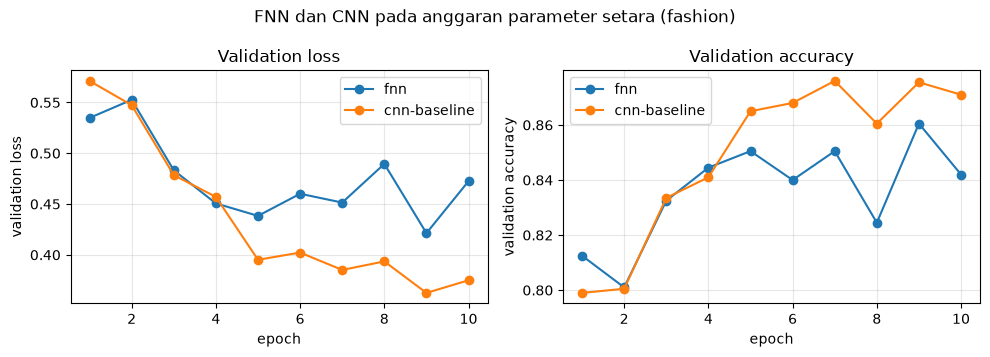

In [65]:
BATCH, EPOCH = 128, 10

cnn_tugas = buat_cnn(c_in=C_IN, hw=H)
p_cnn = sum(q.numel() for q in cnn_tugas.parameters())
d_in = C_IN * H * W_IMG
kandidat = range(max(1, (p_cnn - 10) // (d_in + 11) - 2), (p_cnn - 10) // (d_in + 11) + 3)
hidden = min(kandidat, key=lambda h: abs((d_in + 11) * h + 10 - p_cnn))
fnn_tugas = buat_fnn(hidden, c_in=C_IN, hw=H)
p_fnn = sum(q.numel() for q in fnn_tugas.parameters())
print(f'hidden={hidden} | parameter FNN={p_fnn:,} | CNN={p_cnn:,} | selisih={100 * abs(p_fnn - p_cnn) / p_cnn:.3f}%')
assert abs(p_fnn - p_cnn) / p_cnn < 0.01

def loader(ds, batch, acak):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak, generator=g if acak else None, num_workers=0)

@torch.no_grad()
def evaluasi(model, ds, batch=512):
    model.eval()
    dl = loader(ds, batch, False)
    loss_fn = nn.CrossEntropyLoss(reduction='sum')
    total_loss = 0.0
    benar = 0
    jumlah = 0
    for xb, yb in dl:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += loss_fn(logits, yb).item()
        benar += (logits.argmax(1) == yb).sum().item()
        jumlah += yb.numel()
    return total_loss / jumlah, benar / jumlah

def jumlah_perkalian(model):
    return int(anatomi(model, (C_IN, H, W_IMG))['perkalian'].sum())

def jalankan(model, label, epoch=EPOCH):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    dl = loader(ds_latih, BATCH, True)
    riwayat = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_acc': [], 'detik_per_epoch': []}
    n_update = 0
    for ep in range(1, epoch + 1):
        model.train()
        mulai = time.perf_counter()
        total_loss, jumlah = 0.0, 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * yb.numel()
            jumlah += yb.numel()
            n_update += 1
        durasi = time.perf_counter() - mulai
        train_loss = total_loss / jumlah
        val_loss, val_acc = evaluasi(model, ds_val)
        riwayat['epoch'].append(ep)
        riwayat['train_loss'].append(train_loss)
        riwayat['val_loss'].append(val_loss)
        riwayat['val_acc'].append(val_acc)
        riwayat['detik_per_epoch'].append(durasi)
        print(f'{label} epoch {ep}/{epoch}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, {durasi:.1f}s')
    anat = anatomi(model, (C_IN, H, W_IMG))
    catatan = {'run_id': label, 'seed': SEED, 'dataset': DATASET,
               'arsitektur': str(model), 'parameter': sum(q.numel() for q in model.parameters()),
               'perkalian': int(anat['perkalian'].sum()), 'n_update': n_update,
               'train_loss': riwayat['train_loss'][-1], 'val_loss': riwayat['val_loss'][-1],
               'val_acc': riwayat['val_acc'][-1], 'gap': riwayat['val_loss'][-1] - riwayat['train_loss'][-1],
               'detik_per_epoch': float(np.mean(riwayat['detik_per_epoch'])), 'catatan': ''}
    return riwayat, catatan

hasil, kurva, model_terlatih = [], {}, {}
for model, label in [(fnn_tugas, 'fnn'), (cnn_tugas, 'cnn-baseline')]:
    riwayat, catatan = jalankan(model, label)
    hasil.append(catatan)
    kurva[label] = riwayat
    model_terlatih[label] = model

tabel = pd.DataFrame(hasil)
display(tabel[['run_id', 'parameter', 'perkalian', 'n_update', 'train_loss', 'val_loss', 'val_acc', 'gap', 'detik_per_epoch']])
assert set(tabel['n_update']) == {790}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for label, r in kurva.items():
    axes[0].plot(r['epoch'], r['val_loss'], marker='o', label=label)
    axes[1].plot(r['epoch'], r['val_acc'], marker='o', label=label)
axes[0].set(xlabel='epoch', ylabel='validation loss', title='Validation loss')
axes[1].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy')
for ax in axes: ax.grid(alpha=.3); ax.legend()
fig.suptitle(f'FNN dan CNN pada anggaran parameter setara ({DATASET})')
plt.tight_layout(); display(fig); plt.close(fig)


In [66]:
pemenang = tabel.sort_values('val_acc', ascending=False).iloc[0]
cn = tabel.set_index('run_id')
rasio_waktu_epoch = cn.loc['cnn-baseline','detik_per_epoch'] / cn.loc['fnn','detik_per_epoch']
display(Markdown(f"Model dengan validation accuracy tertinggi adalah **{pemenang['run_id']}** ({pemenang['val_acc']:.3f}), selisih accuracy {abs(cn.loc['cnn-baseline','val_acc']-cn.loc['fnn','val_acc']):.3f}. Rasio waktu per epoch CNN/FNN {rasio_waktu_epoch:.2f}; bandingkan dengan rasio operasi sekitar {rasio_perkalian:.2f}. CNN memakai konektivitas lokal dan parameter sharing; waktu aktual juga dipengaruhi implementasi kernel, bandwidth memori, dan overhead."))


Model dengan validation accuracy tertinggi adalah **cnn-baseline** (0.871), selisih accuracy 0.029. Rasio waktu per epoch CNN/FNN 8.02; bandingkan dengan rasio operasi sekitar 11.24. CNN memakai konektivitas lokal dan parameter sharing; waktu aktual juga dipengaruhi implementasi kernel, bandwidth memori, dan overhead.

## Tugas T3. Kernel, feature map, dan kernel Sobel manual — bagian dari 20 poin

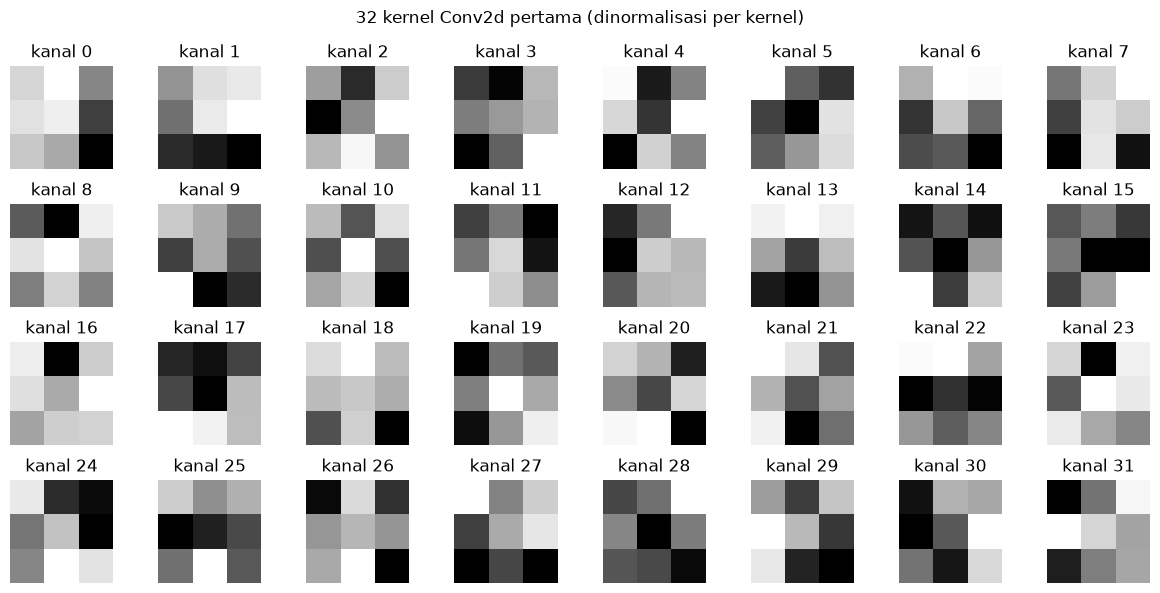

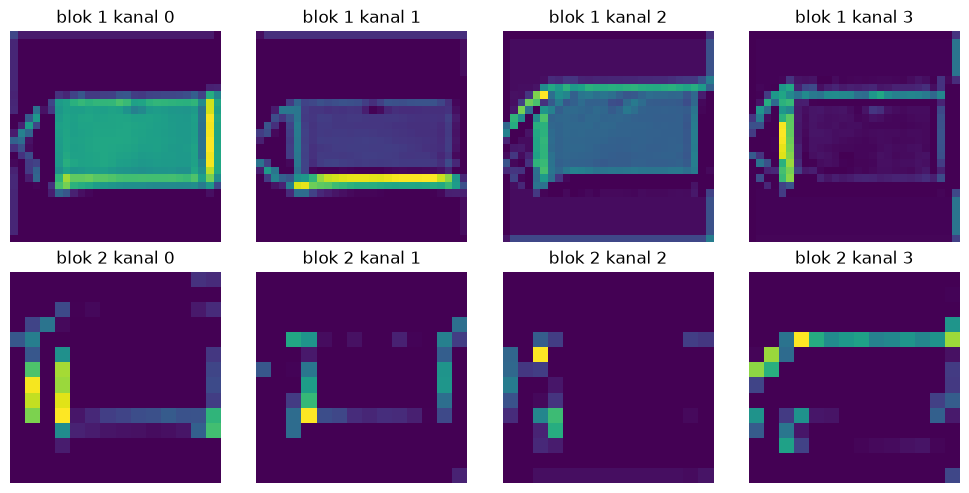

[OK] Sobel x vs F.conv2d: shape (26, 26)
[OK] Sobel y vs F.conv2d: shape (26, 26)


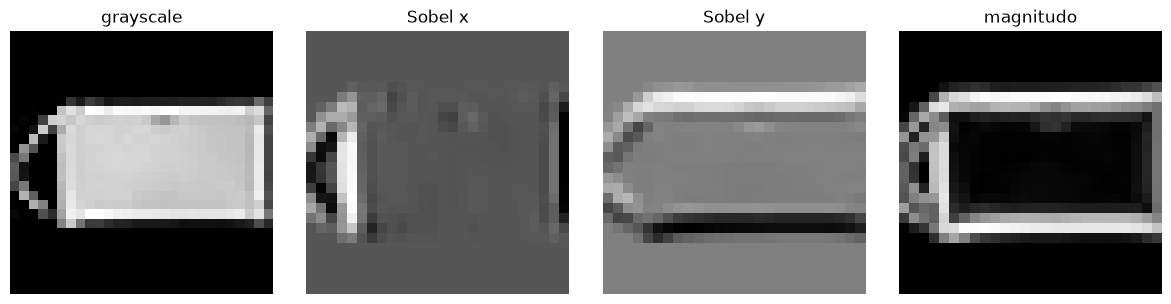

In [68]:
# Kernel conv1, feature maps dua blok, dan pembanding Sobel untuk ds_val[0].
model_cnn = model_terlatih['cnn-baseline'].to(DEVICE).eval()
conv1 = model_cnn[0]
weights = conv1.weight.detach().cpu()
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    k = weights[i].permute(1, 2, 0).numpy()
    lo, hi = k.min(), k.max()
    k = (k - lo) / (hi - lo + 1e-12)
    if k.shape[-1] == 1:
        ax.imshow(k[..., 0], cmap='gray')
    else:
        ax.imshow(k)
    ax.set_title(f'kanal {i}'); ax.axis('off')
fig.suptitle('32 kernel Conv2d pertama (dinormalisasi per kernel)'); plt.tight_layout(); display(fig); plt.close(fig)

x0, y0 = ds_val[0]
with torch.no_grad():
    z1 = model_cnn[1](model_cnn[0](x0[None].to(DEVICE)))
    p1 = model_cnn[2](z1)
    z2 = model_cnn[4](model_cnn[3](p1))
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes[0]): ax.imshow(z1[0, i].cpu(), cmap='viridis'); ax.set_title(f'blok 1 kanal {i}'); ax.axis('off')
for i, ax in enumerate(axes[1]): ax.imshow(z2[0, i].cpu(), cmap='viridis'); ax.set_title(f'blok 2 kanal {i}'); ax.axis('off')
plt.tight_layout(); display(fig); plt.close(fig)

abu = ((x0.to(DEVICE) * STD[0].to(DEVICE) + MEAN[0].to(DEVICE)).mean(dim=0)).to(DT)
sobel_x = torch.tensor([[-1.,0.,1.],[-2.,0.,2.],[-1.,0.,1.]], dtype=DT, device=DEVICE)
sobel_y = sobel_x.T.contiguous()
gray_batch = abu[None, None]
gx = corr2d(abu, sobel_x); gy = corr2d(abu, sobel_y)
cek('Sobel x vs F.conv2d', gx, F.conv2d(gray_batch, sobel_x[None,None])[0,0])
cek('Sobel y vs F.conv2d', gy, F.conv2d(gray_batch, sobel_y[None,None])[0,0])
mag = torch.sqrt(gx.square() + gy.square())
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, im, title in zip(axes, [abu, gx, gy, mag], ['grayscale', 'Sobel x', 'Sobel y', 'magnitudo']): ax.imshow(im.detach().cpu(), cmap='gray'); ax.set_title(title); ax.axis('off')
plt.tight_layout(); display(fig); plt.close(fig)


Feature map blok pertama cenderung menonjolkan pola lokal/tepi; blok kedua menggabungkan pola yang lebih luas dan abstrak. Bandingkan kernel terlatih dengan visualisasi Sobel; kemiripan dapat dinilai dari orientasi respons positif/negatif.


## Tugas T4. Evaluasi akhir — bagian dari 20 poin

model terpilih: cnn-baseline


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
T-shirt/top,151,0,6,13,3,1,24,0,2,0
Trouser,0,196,0,0,2,0,0,0,2,0
Pullover,0,1,170,4,13,1,10,0,1,0
Dress,1,4,2,183,5,0,4,0,1,0
Coat,0,0,19,10,166,0,3,0,2,0
Sandal,0,0,0,0,0,188,0,11,0,1
Shirt,21,1,28,8,35,0,106,0,1,0
Sneaker,0,0,0,0,0,0,0,196,0,4
Bag,2,0,0,1,2,1,1,0,193,0
Ankle boot,0,0,0,0,0,2,0,5,0,193


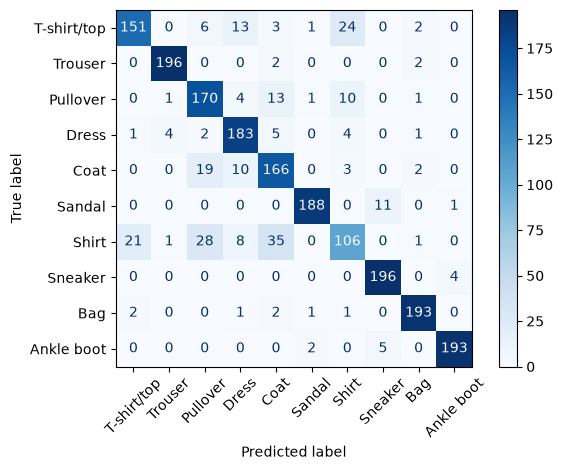

pasangan paling sering tertukar: Shirt → Coat (35 kasus satu arah)


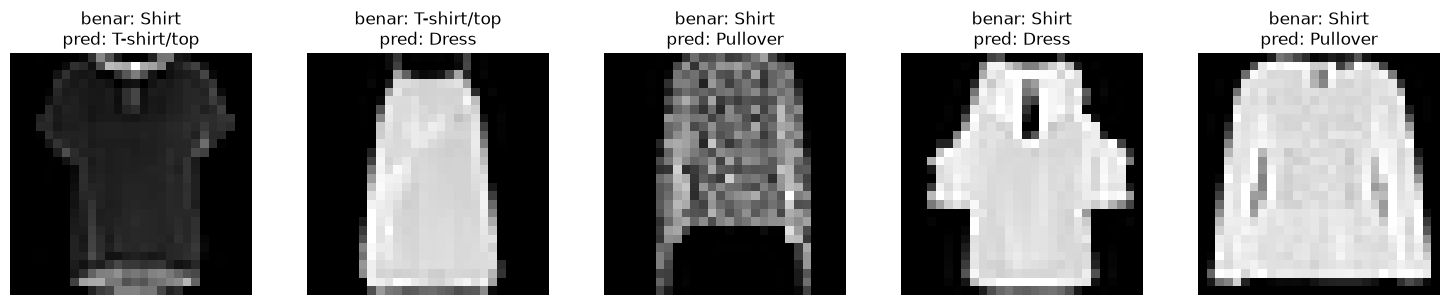

,No,Label benar,Prediksi,Dugaan penyebab
0,1,Shirt,T-shirt/top,Kelas memiliki bentuk/tekstur atau warna yang ...
1,2,T-shirt/top,Dress,Kelas memiliki bentuk/tekstur atau warna yang ...
2,3,Shirt,Pullover,Kelas memiliki bentuk/tekstur atau warna yang ...
3,4,Shirt,Dress,Kelas memiliki bentuk/tekstur atau warna yang ...
4,5,Shirt,Pullover,Kelas memiliki bentuk/tekstur atau warna yang ...


test dievaluasi satu kali: loss=0.3487, accuracy=0.8802
metrics disimpan ke M05_122450138_metrics.csv


In [69]:
# Pilih model berdasar validation loss; test set baru disentuh pada bagian akhir ini.
terpilih = min(hasil, key=lambda r: r['val_loss'])['run_id']
model_pilih = model_terlatih[terpilih].eval()
print('model terpilih:', terpilih)

def prediksi(ds, model, batch=512):
    model.eval(); ys=[]; ps=[]
    with torch.no_grad():
        for xb, yb in loader(ds, batch, False):
            logits = model(xb.to(DEVICE))
            ps.append(logits.argmax(1).cpu()); ys.append(yb.cpu())
    return torch.cat(ys), torch.cat(ps)

y_true, y_pred = prediksi(ds_val, model_pilih)
cm = confusion_matrix(y_true.numpy(), y_pred.numpy(), labels=np.arange(len(KELAS)))
display(pd.DataFrame(cm, index=KELAS, columns=KELAS))
ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(xticks_rotation=45, cmap='Blues', values_format='d')
plt.tight_layout(); plt.show()
cm_pair = cm.copy(); np.fill_diagonal(cm_pair, 0)
a, b = np.unravel_index(cm_pair.argmax(), cm_pair.shape)
print(f'pasangan paling sering tertukar: {KELAS[a]} → {KELAS[b]} ({cm_pair[a,b]} kasus satu arah)')

salah = (y_true != y_pred).nonzero().flatten()[:5]
baris_salah=[]
fig, axes=plt.subplots(1, max(1,len(salah)), figsize=(3*max(1,len(salah)),3))
if len(salah)==1: axes=[axes]
for ax, ix in zip(axes, salah.tolist()):
    xx, yy=ds_val[ix]
    raw=(xx*STD[0]+MEAN[0]).clamp(0,1).permute(1,2,0)
    if raw.shape[-1]==1: ax.imshow(raw[...,0], cmap='gray')
    else: ax.imshow(raw)
    ax.set_title(f'benar: {KELAS[int(yy)]}\npred: {KELAS[int(y_pred[ix])]}'); ax.axis('off')
    baris_salah.append({'No':len(baris_salah)+1,'Label benar':KELAS[int(yy)],'Prediksi':KELAS[int(y_pred[ix])], 'Dugaan penyebab':'Kelas memiliki bentuk/tekstur atau warna yang mirip.'})
plt.tight_layout(); plt.show()
tabel_salah=pd.DataFrame(baris_salah); display(tabel_salah)

# Satu-satunya evaluasi pada test resmi.
ds_uji=TensorDataset(normalkan(X_uji_mentah), y_uji)
test_loss, test_acc=evaluasi(model_pilih, ds_uji)
print(f'test dievaluasi satu kali: loss={test_loss:.4f}, accuracy={test_acc:.4f}')

metrics=tabel.copy()
metrics['test_loss']=np.nan; metrics['test_acc']=np.nan
metrics.loc[metrics.run_id==terpilih,'test_loss']=test_loss
metrics.loc[metrics.run_id==terpilih,'test_acc']=test_acc
metrics.to_csv('M05_122450138_metrics.csv', index=False)
print('metrics disimpan ke M05_122450138_metrics.csv')


**Lima kesalahan validasi:** tabel berisi nomor, kelas benar, prediksi, dan dugaan penyebab ditampilkan tepat di atas. Pasangan kelas yang paling sering tertukar dan confusion matrix juga dicetak pada bagian sebelumnya. Kesalahan umumnya muncul pada kategori dengan bentuk/tekstur atau warna yang mirip, serta objek kecil atau tertutup sebagian.


In [70]:
tabel_metrics = tabel.copy()
tabel_metrics.insert(0, 'module', 'M05')
tabel_metrics.insert(1, 'student_id', NIM)
tabel_metrics.to_csv(f'M05_{NIM}_metrics.csv', index=False)
print(f'{len(tabel_metrics)} baris tersimpan ke M05_{NIM}_metrics.csv')
assert len(tabel_metrics) == 2, 'metrics.csv harus memuat run FNN dan CNN baseline'

2 baris tersimpan ke M05_122450138_metrics.csv


In [71]:
winner = tabel.sort_values('val_loss').iloc[0]['run_id']
display(Markdown(f"""1. Gradien masukan membalik kernel saat kontribusi dari keluaran tetangga disejajarkan. Untuk X₁₁ pada contoh, ∂L/∂X₁₁ = 1·0 + 0·2 + (−1)·(−1) + 2·1 = 3. Gradien kernel memakai patch masukan dan gradien keluaran yang sejajar.
2. Dengan stride 2, baris/kolom yang tidak terliput jendela tidak memberi kontribusi dan gradiennya nol.
3. Pada anggaran parameter sebanding, validation accuracy FNN adalah {cn.loc['fnn','val_acc']:.3f} dan CNN {cn.loc['cnn-baseline','val_acc']:.3f}; model dengan accuracy tertinggi ialah {pemenang['run_id']}. Konektivitas lokal dan parameter sharing memberi CNN bias induktif yang sesuai untuk citra.
4. Rasio waktu per epoch CNN/FNN {rasio_waktu_epoch:.2f}, dibanding rasio perkalian {rasio_perkalian:.2f}. Perbedaan timbul dari kernel teroptimasi, akses memori, dan overhead framework.
5. Receptive field 10×10 hanya mencakup sebagian objek 32×32. Flatten lalu layer Linear menggabungkan informasi dari seluruh lokasi spasial. Model terpilih untuk evaluasi akhir: {winner}."""))


1. Gradien masukan membalik kernel saat kontribusi dari keluaran tetangga disejajarkan. Untuk X₁₁ pada contoh, ∂L/∂X₁₁ = 1·0 + 0·2 + (−1)·(−1) + 2·1 = 3. Gradien kernel memakai patch masukan dan gradien keluaran yang sejajar.
2. Dengan stride 2, baris/kolom yang tidak terliput jendela tidak memberi kontribusi dan gradiennya nol.
3. Pada anggaran parameter sebanding, validation accuracy FNN adalah 0.842 dan CNN 0.871; model dengan accuracy tertinggi ialah cnn-baseline. Konektivitas lokal dan parameter sharing memberi CNN bias induktif yang sesuai untuk citra.
4. Rasio waktu per epoch CNN/FNN 8.02, dibanding rasio perkalian 11.24. Perbedaan timbul dari kernel teroptimasi, akses memori, dan overhead framework.
5. Receptive field 10×10 hanya mencakup sebagian objek 32×32. Flatten lalu layer Linear menggabungkan informasi dari seluruh lokasi spasial. Model terpilih untuk evaluasi akhir: cnn-baseline.

## Checklist sebelum mengumpulkan

- [ ] Identitas, seed, versi library, device, dan dataset tercantum.
- [ ] Setiap hitungan tangan berada pada sel sebelum kode verifikasinya.
- [ ] Implementasi manual tidak memanggil `F.conv2d` maupun autograd.
- [ ] Seluruh sel `cek` dan `assert` lolos pada `float64`.
- [ ] Tabel anatomi memuat shape, parameter, perkalian, dan receptive field untuk kedua model.
- [ ] Kedua run memakai data, seed, dan 790 update yang sama.
- [ ] Test set hanya dipanggil satu kali pada Tugas T4.
- [ ] `metrics.csv` memuat kedua run.
- [ ] Notebook lolos *Restart Kernel and Run All*.